| **Inicio**         | **atrás 2**                          | **Siguiente 4**                                    |
| ------------------ | ------------------------------------ | -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./5_2_Sistemas_dinamicos.ipynb) | [⏩](./5_4_Fourier.ipynb) |

# 1. ¿Qué es un sistema lineal?

Empecemos con algo algebraico:

$
\begin{cases}
2x+3y=7\\
4x-y=5
\end{cases}
$

Esto puede escribirse como

$
Ax=b
$

donde

$
A=
\begin{bmatrix}
2&3\\
4&-1
\end{bmatrix},
\qquad
x=
\begin{bmatrix}
x\\y
\end{bmatrix},
\qquad
b=
\begin{bmatrix}
7\\5
\end{bmatrix}
$

Esto es un **sistema lineal algebraico**.

Pero en SciML nos interesará muchísimo otro tipo:

$
\boxed{
\frac{d\mathbf{x}}{dt}=A\mathbf{x}
}
$

Ahora las incógnitas no son simplemente números.

Son **funciones del tiempo**.

Por ejemplo:

$
\mathbf{x}(t)=
\begin{bmatrix}
x_1(t)\\
x_2(t)
\end{bmatrix}
$

Y podemos tener:

$
\begin{cases}
x_1'(t)=-2x_1(t)+x_2(t)\\
x_2'(t)=3x_1(t)-4x_2(t)
\end{cases}
$

o matricialmente:

$
\boxed{
\mathbf{x}'=
\begin{bmatrix}
-2&1\\
3&-4
\end{bmatrix}
\mathbf{x}
}
$

Aquí aparecen simultáneamente:

- **álgebra lineal:** matriz $(A)$, autovalores y autovectores;
- **cálculo:** derivadas, exponenciales, integración;
- **ODE:** evolución temporal del sistema.

Esta ecuación aparentemente sencilla es una de las estructuras fundamentales de modelado científico.

# 2. Interpretación física de $(x'=Ax)$

Supongamos:

$
\mathbf{x}(t)=
\begin{bmatrix}
x(t)\\
y(t)
\end{bmatrix}$

Entonces

$\mathbf{x}'(t)=
\begin{bmatrix}
x'(t)\\
y'(t)
\end{bmatrix}$

Si

$A=
\begin{bmatrix}
a&b\\
c&d
\end{bmatrix}$

entonces

$
\begin{bmatrix}
x'\\
y'
\end{bmatrix}
=$
$\begin{bmatrix}
a&b\\
c&d
\end{bmatrix}
\begin{bmatrix}
x\\
y
\end{bmatrix}$

Multiplicando:

$\boxed{x'=ax+by}$

$\boxed{y'=cx+dy}$

Esto significa algo importante:

> El estado actual $(x,y)$ determina instantáneamente la dirección en la que evolucionará el sistema.

Por ejemplo:

$A=
\begin{bmatrix}
-1&2\\
-2&-1
\end{bmatrix}$

Tenemos

$x'=-x+2y$

$y'=-2x-y$

Supongamos que actualmente:

$(x,y)=(2,1)$

Entonces:

$x'=-2+2(1)=0$

y

$y'=-4-1=-5$

Por tanto:

$\mathbf{x}'=
\begin{bmatrix}
0\\
-5
\end{bmatrix}$

El sistema, en ese instante, se mueve fuertemente hacia abajo.

Esta interpretación será fundamental para entender los **campos vectoriales**.

# 3. Primer gráfico importante: campo vectorial

Para cada punto $(x,y)$, calculamos:

$\mathbf{x}'=A\mathbf{x}$

Python:

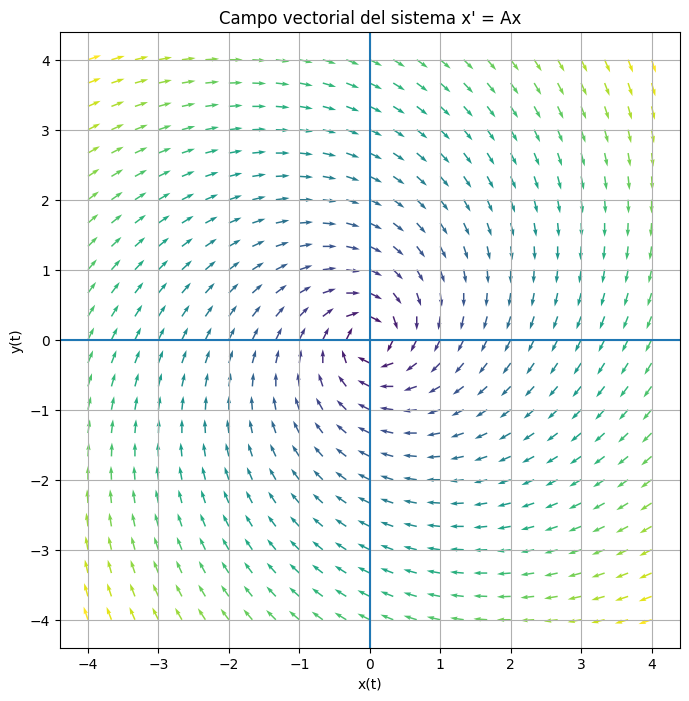

In [1]:
import numpy as np
import matplotlib.pyplot as plt

A = np.array([
    [-1,  2],
    [-2, -1]
])

x = np.linspace(-4, 4, 25)
y = np.linspace(-4, 4, 25)

X, Y = np.meshgrid(x, y)

U = A[0, 0] * X + A[0, 1] * Y
V = A[1, 0] * X + A[1, 1] * Y

speed = np.sqrt(U**2 + V**2)

# Normalización solo para visualizar mejor las direcciones
U_norm = U / (speed + 1e-12)
V_norm = V / (speed + 1e-12)

plt.figure(figsize=(8, 8))

plt.quiver(
    X, Y,
    U_norm, V_norm,
    speed
)

plt.xlabel("x(t)")
plt.ylabel("y(t)")
plt.title("Campo vectorial del sistema x' = Ax")
plt.axhline(0)
plt.axvline(0)
plt.grid()

plt.show()

Lo que estás dibujando realmente es:

$(x,y)
\longrightarrow
(x',y')$

Cada flecha responde:

> Si el sistema se encuentra aquí, ¿hacia dónde comienza a moverse?

Esta idea aparece constantemente en sistemas dinámicos, física y SciML.

# 4. ¿Cómo resolvemos $(x'=Ax)$?

Aquí ocurre una conexión preciosa entre cálculo y álgebra lineal.

Primero recuerda la ODE escalar:

$x'=ax$

Su solución es:

$x(t)=Ce^{at}$

Porque:

$\frac{d}{dt}Ce^{at}=aCe^{at}$

Para matrices ocurre algo análogo:


$\boxed{
\mathbf{x}(t)=e^{At}\mathbf{x}_0
}$

donde $(e^{At})$ es la **exponencial matricial**.

La analogía es:

$x'=ax
\quad\rightarrow\quad
x(t)=e^{at}x_0$

y


$\mathbf{x}'=A\mathbf{x}
\quad\rightarrow\quad
\mathbf{x}(t)=e^{At}\mathbf{x}_0$

Pero ¿qué demonios significa elevar $(e)$ a una matriz?

# 5. Exponencial matricial

Recordemos la serie de Taylor:

$e^x
=$
$1+x+\frac{x^2}{2!}+\frac{x^3}{3!}+\cdots$

Sustituimos $(x)$ por una matriz:

$e^{At}
=$
$I+At+\frac{(At)^2}{2!}
+\frac{(At)^3}{3!}
+\cdots
$

Entonces:

$\mathbf{x}(t)=e^{At}\mathbf{x}_0$

En Python no tenemos que calcular la serie manualmente.

SciPy proporciona:

```python
from scipy.linalg import expm
```

Ejemplo:

In [2]:
import numpy as np
from scipy.linalg import expm

A = np.array([
    [-1,  2],
    [-2, -1]
])

x0 = np.array([3.0, 1.0])

t = 2.0

x_t = expm(A * t) @ x0

print(x_t)

[-0.36780521  0.2188052 ]


Aquí:

```python
expm(A * t)
```

calcula

$e^{At}$

y

```python
@ x0
```

calcula

$e^{At}x_0$

# 6. Aquí entran los autovalores

Supongamos:

$A v=\lambda v$

Entonces $(v)$ es un autovector y $(\lambda)$ su autovalor.

Ahora supongamos que la condición inicial está exactamente sobre ese autovector:

$x(0)=v$

La solución será:

$x(t)=e^{At}v$

Como

$Av=\lambda v$

resulta:

$\boxed{x(t)=e^{\lambda t}v}$

Esto es extremadamente importante.

Significa que cada autovector representa una **dirección natural de evolución del sistema**, mientras que el autovalor determina cómo evoluciona esa dirección.

Si:

$\lambda<0$

entonces

$e^{\lambda t}\rightarrow0$

La componente desaparece.

Si:

$\lambda>0$

entonces

$e^{\lambda t}\rightarrow\infty$

La componente crece.

Si:

$\lambda=a+bi$

aparecen oscilaciones.

# 7. Ejemplo difícil: sistema dinámico estable

Consideremos:

$A=
\begin{bmatrix}
-1&2\\
2&-4
\end{bmatrix}$

Queremos analizar:

$x'=Ax$

Primero calculamos los autovalores.

In [3]:
import numpy as np

A = np.array([
    [-1, 2],
    [ 2,-4]
], dtype=float)

eigenvalues, eigenvectors = np.linalg.eig(A)

print("Autovalores:")
print(eigenvalues)

print("\nAutovectores:")
print(eigenvectors)

Autovalores:
[ 0. -5.]

Autovectores:
[[ 0.89442719 -0.4472136 ]
 [ 0.4472136   0.89442719]]


Aproximadamente obtenemos:

$\lambda_1\approx0$

$\lambda_2\approx-5$

Esto ya nos cuenta casi toda la historia dinámica.

Una dirección no desaparece porque:

$e^{0t}=1$

La otra desaparece rápidamente:

$e^{-5t}\rightarrow0$

Por tanto, diferentes condiciones iniciales terminarán acercándose a una determinada dirección.

# 8. Dibujemos las trayectorias

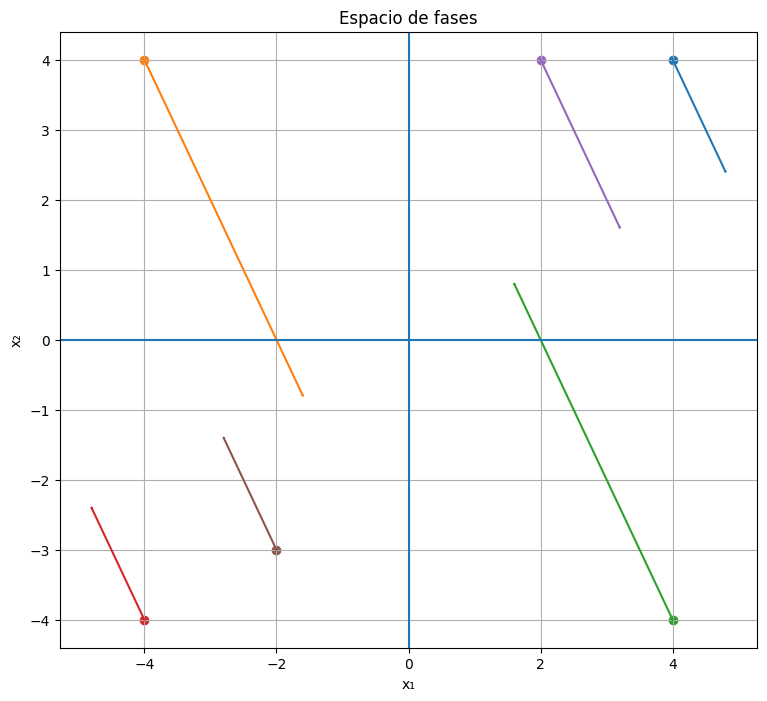

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

A = np.array([
    [-1, 2],
    [ 2,-4]
], dtype=float)


def system(t, state):
    return A @ state


initial_conditions = [
    [4, 4],
    [-4, 4],
    [4, -4],
    [-4, -4],
    [2, 4],
    [-2, -3]
]

t_span = (0, 5)

plt.figure(figsize=(9, 8))

for x0 in initial_conditions:

    sol = solve_ivp(
        system,
        t_span,
        x0,
        dense_output=True
    )

    t = np.linspace(0, 5, 500)

    trajectory = sol.sol(t)

    plt.plot(
        trajectory[0],
        trajectory[1]
    )

    plt.scatter(
        trajectory[0, 0],
        trajectory[1, 0]
    )

plt.xlabel("x₁")
plt.ylabel("x₂")

plt.title("Espacio de fases")

plt.axhline(0)
plt.axvline(0)

plt.grid()

plt.show()

Observa algo conceptualmente importante: el eje horizontal del gráfico **no es el tiempo**.

Tenemos:

$x=x_1(t)$

$y=x_2(t)$

Estamos eliminando visualmente $(t)$ y dibujando:

$(x_1(t),x_2(t))$

Esto se denomina **espacio de fases**.

# 9. Ahora veamos las variables contra el tiempo

El mismo sistema puede visualizarse de otra forma:

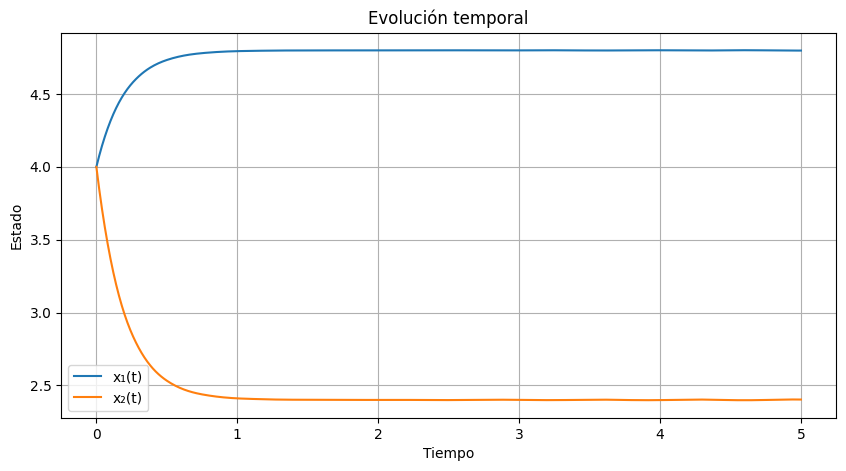

In [5]:
x0 = [4, 4]

sol = solve_ivp(
    system,
    (0, 5),
    x0,
    dense_output=True
)

t = np.linspace(0, 5, 500)

x = sol.sol(t)

plt.figure(figsize=(10, 5))

plt.plot(t, x[0], label="x₁(t)")
plt.plot(t, x[1], label="x₂(t)")

plt.xlabel("Tiempo")
plt.ylabel("Estado")

plt.title("Evolución temporal")

plt.legend()
plt.grid()

plt.show()

Ahora sí tenemos:

$t\rightarrow x_1(t)$

y

$t\rightarrow x_2(t)$

Los dos gráficos describen **exactamente el mismo fenómeno**, pero responden preguntas diferentes.

# 10. Ejemplo de vida real: suspensión de un automóvil

Aquí aparece un ejemplo mucho más interesante.



Cuando un automóvil pasa por un bache, la suspensión oscila.

Una simplificación física es:

$m\frac{d^2x}{dt^2}
+
c\frac{dx}{dt}
+
kx
=0
$

donde:

- $(m)$: masa;
- $(c)$: amortiguamiento;
- $(k)$: rigidez del resorte;
- $(x(t))$: desplazamiento vertical.

Tenemos una ODE de **segundo orden**.

Por ejemplo:

$m=250\;kg$

$c=1000\;Ns/m$

$k=15000\;N/m$

Entonces:


$250x''+1000x'+15000x=0$

Dividimos entre 250:

$x''+4x'+60x=0$

# 11. Convertimos la ODE en álgebra lineal

Definimos:

$x_1=x$

y

$x_2=x'$

Entonces:

$x_1'=x_2$

Además:

$x''=-4x'-60x$

Por tanto:

$x_2'=-60x_1-4x_2$

Tenemos:

$\begin{cases}
x_1'=x_2\\
x_2'=-60x_1-4x_2
\end{cases}$

o:


$\begin{bmatrix}
x_1'\\
x_2'
\end{bmatrix}
=$
$\begin{bmatrix}
0&1\\
-60&-4
\end{bmatrix}
\begin{bmatrix}
x_1\\
x_2
\end{bmatrix}
$

Fíjate en lo que acabamos de hacer:

$\boxed{
\text{ODE de segundo orden}
\rightarrow
\text{sistema de ODE de primer orden}
\rightarrow
\text{álgebra lineal}
}$

Esta transformación es fundamental para SciML.

# 12. Simulación completa de la suspensión

Supongamos que un bache desplaza inicialmente la rueda/carrocería unos:

$x(0)=0.10m$

Y inicialmente:

$v(0)=0$

Python:

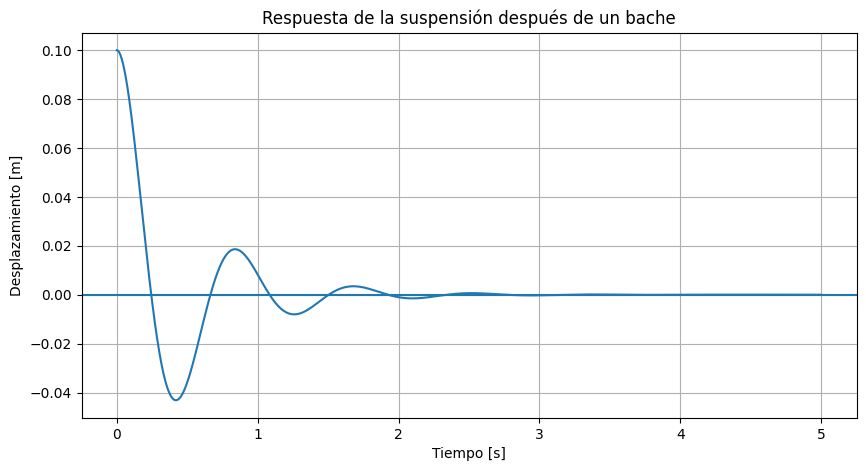

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

m = 250.0
c = 1000.0
k = 15000.0


def suspension(t, state):

    x, v = state

    dxdt = v

    dvdt = -(c/m)*v - (k/m)*x

    return [dxdt, dvdt]


x0 = [
    0.10,   # desplazamiento inicial
    0.0     # velocidad inicial
]

t_span = (0, 5)

t_eval = np.linspace(
    t_span[0],
    t_span[1],
    1000
)

solution = solve_ivp(
    suspension,
    t_span,
    x0,
    t_eval=t_eval
)

t = solution.t

x = solution.y[0]
v = solution.y[1]


plt.figure(figsize=(10, 5))

plt.plot(t, x)

plt.xlabel("Tiempo [s]")
plt.ylabel("Desplazamiento [m]")

plt.title("Respuesta de la suspensión después de un bache")

plt.axhline(0)

plt.grid()

plt.show()

Deberías observar una oscilación cuya amplitud disminuye.

Físicamente:

$\text{resorte}
\rightarrow \text{produce oscilación}$

mientras que

$\text{amortiguador}
\rightarrow \text{disipa energía}$

# 13. Espacio de fases de la suspensión

Ahora hacemos algo mucho más interesante.

Representamos:

$(x(t),v(t))$

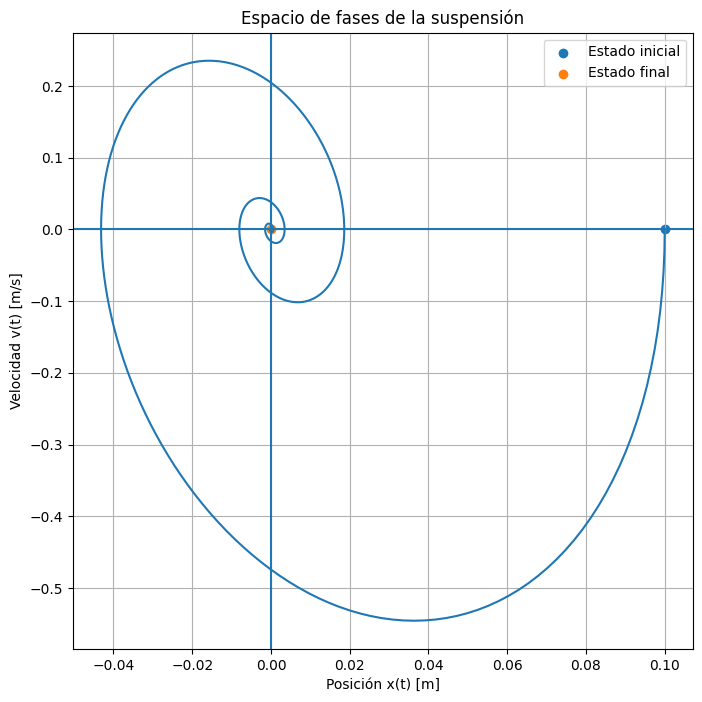

In [7]:
plt.figure(figsize=(8, 8))

plt.plot(x, v)

plt.scatter(
    x[0],
    v[0],
    label="Estado inicial"
)

plt.scatter(
    x[-1],
    v[-1],
    label="Estado final"
)

plt.xlabel("Posición x(t) [m]")
plt.ylabel("Velocidad v(t) [m/s]")

plt.title("Espacio de fases de la suspensión")

plt.axhline(0)
plt.axvline(0)

plt.legend()
plt.grid()

plt.show()

Obtendrás aproximadamente una espiral hacia:

$(x,v)=(0,0)$

¿Por qué?

Porque el automóvil finalmente vuelve al equilibrio:

$x\rightarrow0$

y

$v\rightarrow0$

Matemáticamente, eso está relacionado con los autovalores de:

$A=
\begin{bmatrix}
0&1\\
-60&-4
\end{bmatrix}$

# 14. Calculemos esos autovalores

In [8]:
A = np.array([
    [0, 1],
    [-60, -4]
], dtype=float)

eigenvalues, eigenvectors = np.linalg.eig(A)

print(eigenvalues)

[-2.+7.48331477j -2.-7.48331477j]


Analíticamente resolvemos:

$\det(A-\lambda I)=0$

Tenemos:

$\begin{vmatrix}
-\lambda&1\\
-60&-4-\lambda
\end{vmatrix}=0$

Por tanto:

$\lambda(4+\lambda)+60=0$


$\lambda^2+4\lambda+60=0$

Aplicamos la fórmula cuadrática:

$\lambda=
\frac{-4\pm\sqrt{16-240}}{2}$

$\lambda=
\frac{-4\pm\sqrt{-224}}{2}$

Por tanto:

$\boxed{
\lambda=-2\pm7.483i
}$

Ahora podemos interpretar físicamente estos números.

La parte imaginaria:

$7.483i$

produce **oscilaciones**.

La parte real:

$-2$

produce:

$e^{-2t}$

Es decir, las oscilaciones disminuyen exponencialmente.

Tenemos aproximadamente:

$x(t)
=$
$e^{-2t}
\left[
C_1\cos(7.483t)
+
C_2\sin(7.483t)
\right]$

Aquí acabas de conectar:

$\boxed{
\text{autovalores}
\leftrightarrow
\text{comportamiento físico}
}$

Esto es mucho más importante que simplemente aprender a calcular autovalores.

# 15. Visualicemos el papel del amortiguamiento


Podemos hacer un experimento computacional.

Usaremos diferentes valores de $(c)$:

$c=100$

$c=1000$

$c=4000$

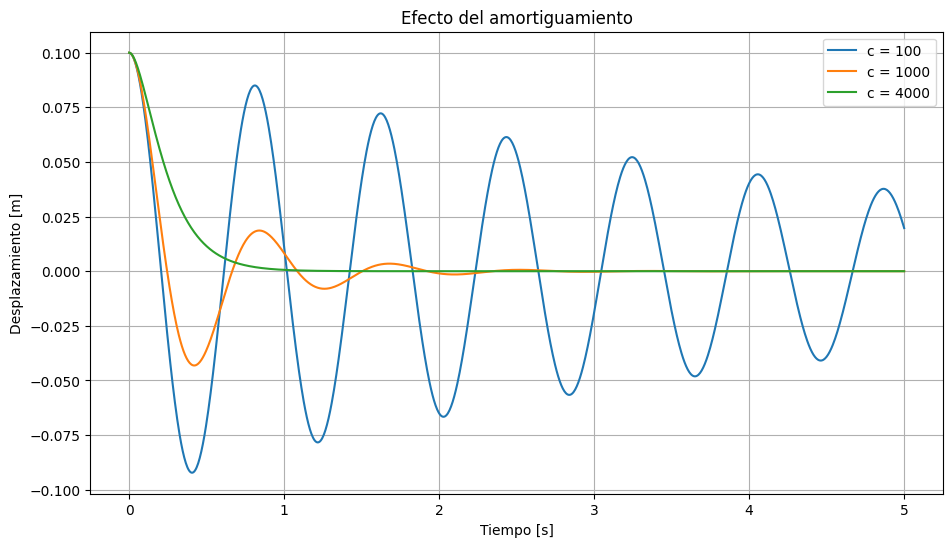

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

m = 250
k = 15000

damping_values = [
    100,
    1000,
    4000
]

t = np.linspace(0, 5, 1000)


def simulate(c):

    def model(t, state):

        x, v = state

        return [
            v,
            -(c/m)*v - (k/m)*x
        ]

    sol = solve_ivp(
        model,
        (0, 5),
        [0.1, 0],
        t_eval=t
    )

    return sol.y[0]


plt.figure(figsize=(11, 6))

for c in damping_values:

    x = simulate(c)

    plt.plot(
        t,
        x,
        label=f"c = {c}"
    )


plt.xlabel("Tiempo [s]")
plt.ylabel("Desplazamiento [m]")

plt.title("Efecto del amortiguamiento")

plt.legend()
plt.grid()

plt.show()

Aquí ya estamos haciendo algo parecido a un experimento científico computacional:

$\text{parámetro}
\rightarrow
\text{modelo}
\rightarrow
\text{simulación}
\rightarrow
\text{observación}$

Eso será extremadamente común en SciML.

# 16. Ejemplo más difícil: edificio sometido a vibraciones

Subamos bastante el nivel.

Supongamos un edificio simplificado de **3 pisos**.



Representamos el desplazamiento horizontal de cada piso mediante:

$x=
\begin{bmatrix}
x_1\\
x_2\\
x_3
\end{bmatrix}$

La ecuación física general es:

$\boxed{
M\ddot{x}+C\dot{x}+Kx=f(t)
}$

Ahora tenemos matrices.

$(M)$ es la matriz de masas.

$(C)$ representa amortiguamiento.

$(K)$ representa rigidez estructural.

$f(t)$ representa fuerzas externas, como un terremoto.

Por ejemplo:

$M=
\begin{bmatrix}
m&0&0\\
0&m&0\\
0&0&m
\end{bmatrix}$

La matriz de rigidez puede ser:

$K=
\begin{bmatrix}
2k&-k&0\\
-k&2k&-k\\
0&-k&k
\end{bmatrix}$

Observa los términos $(-k)$.

Aparecen porque los pisos están **acoplados**.

El movimiento del piso 1 afecta al 2.

El movimiento del 2 afecta tanto al 1 como al 3.

Esto ya es un verdadero **sistema dinámico multivariable**.

# 17. Simulación del edificio

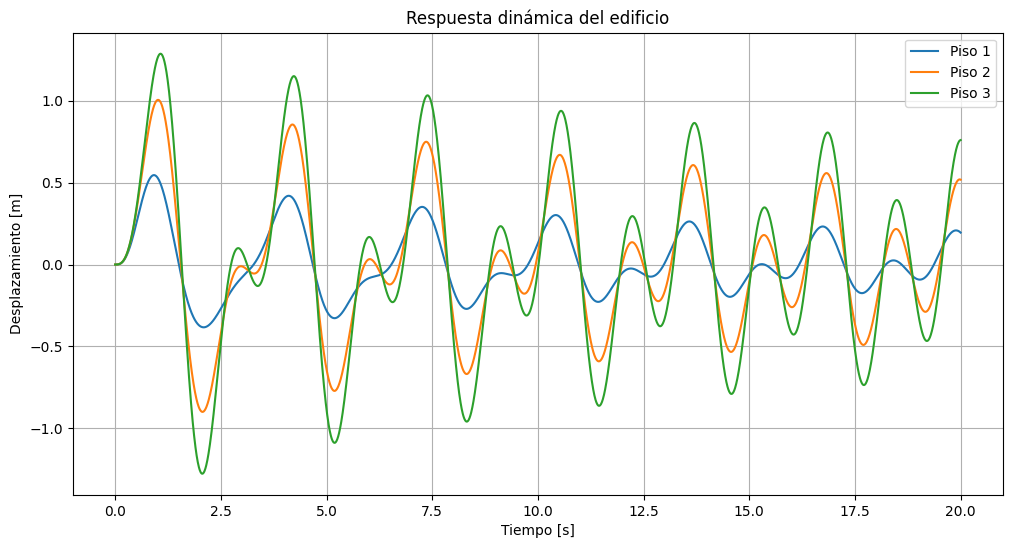

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Número de pisos
n = 3

# Parámetros
m = 1000.0
k = 20000.0
c = 800.0

M = m * np.eye(n)

K = k * np.array([
    [ 2, -1,  0],
    [-1,  2, -1],
    [ 0, -1,  1]
])

C = c * np.array([
    [ 2, -1,  0],
    [-1,  2, -1],
    [ 0, -1,  1]
])

M_inv = np.linalg.inv(M)


def earthquake_force(t):

    # Fuerza oscilatoria externa
    force = 5000 * np.sin(4 * t)

    return np.array([
        force,
        force,
        force
    ])


def building(t, state):

    # Primeros tres estados: posiciones
    x = state[:n]

    # Últimos tres: velocidades
    v = state[n:]

    force = earthquake_force(t)

    a = M_inv @ (
        force
        - C @ v
        - K @ x
    )

    return np.concatenate([
        v,
        a
    ])


initial_state = np.zeros(2*n)

t_eval = np.linspace(
    0,
    20,
    3000
)

solution = solve_ivp(
    building,
    (0, 20),
    initial_state,
    t_eval=t_eval
)

t = solution.t

x1 = solution.y[0]
x2 = solution.y[1]
x3 = solution.y[2]


plt.figure(figsize=(12, 6))

plt.plot(t, x1, label="Piso 1")
plt.plot(t, x2, label="Piso 2")
plt.plot(t, x3, label="Piso 3")

plt.xlabel("Tiempo [s]")
plt.ylabel("Desplazamiento [m]")

plt.title("Respuesta dinámica del edificio")

plt.legend()
plt.grid()

plt.show()

Ahora tenemos:

$6$

variables de estado:

$[x_1,x_2,x_3,v_1,v_2,v_3]$

Y eso significa que realmente estamos resolviendo una dinámica en:

$\mathbb{R}^6$

No podemos visualizar directamente seis dimensiones, pero matemáticamente no hay ningún problema.

# 18. ¿Dónde está el álgebra lineal en el edificio?

Está prácticamente en todas partes.

Tenemos:

$M\ddot{x}+C\dot{x}+Kx=f$

Despejamos:

$\ddot{x}
=$
$M^{-1}
(f-C\dot{x}-Kx)$

Definimos:

$z=
\begin{bmatrix}
x\\
\dot{x}
\end{bmatrix}$

Entonces podemos convertirlo en:

$\boxed{
\dot{z}=Az+Bf
}$

donde:

$A=
\begin{bmatrix}
0&I\\
-M^{-1}K&-M^{-1}C
\end{bmatrix}$

Este patrón aparece por todas partes:

$\boxed{
\text{modelo físico}
\rightarrow
\text{ODE}
\rightarrow
\text{sistema matricial}
}$

# 19. Autovalores y frecuencias naturales

Ahora viene algo especialmente interesante.

Si ignoramos temporalmente el amortiguamiento:

$M\ddot{x}+Kx=0$

Buscamos soluciones oscilatorias.

El problema conduce a:

$Kv=\lambda Mv$

Esto es un **problema de autovalores generalizado**.

Y resulta que:

$\lambda_i=\omega_i^2$

Por tanto:

$\boxed{
\omega_i=\sqrt{\lambda_i}
}
$

son las **frecuencias naturales** del edificio.

Python:

In [11]:
from scipy.linalg import eigh

eigenvalues, modes = eigh(K, M)

omega = np.sqrt(eigenvalues)

frequencies_hz = omega / (2*np.pi)

print("Frecuencias naturales [Hz]:")
print(frequencies_hz)

print("\nModos de vibración:")
print(modes)

Frecuencias naturales [Hz]:
[0.31676413 0.88755337 1.28255179]

Modos de vibración:
[[ 0.01037181 -0.02330523 -0.01868935]
 [ 0.01868935 -0.01037181  0.02330523]
 [ 0.02330523  0.01868935 -0.01037181]]


Los autovectores son ahora físicamente los **modos naturales de vibración**.

Es decir:

$v_1
=$
$\text{forma de vibración 1}$

$v_2
=$
$\text{forma de vibración 2}$

$v_3
=$
$\text{forma de vibración 3}$

Esto demuestra por qué los autovectores no son simplemente un concepto abstracto de un curso de álgebra lineal.

Pueden representar literalmente **cómo se deforma un edificio cuando vibra**.

# 20. Grafiquemos los modos de vibración

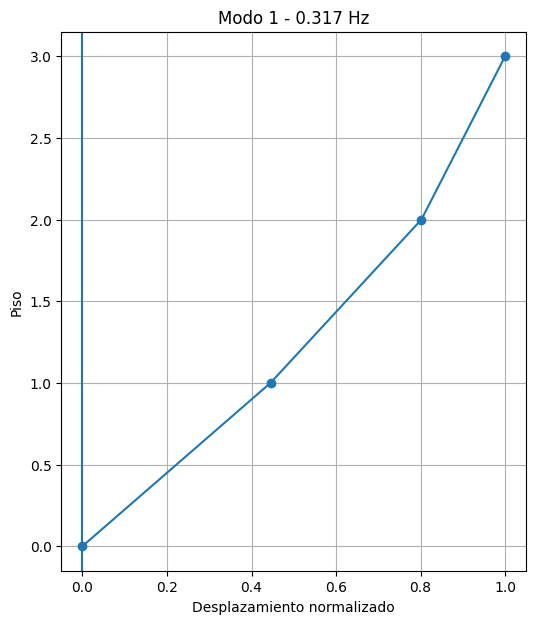

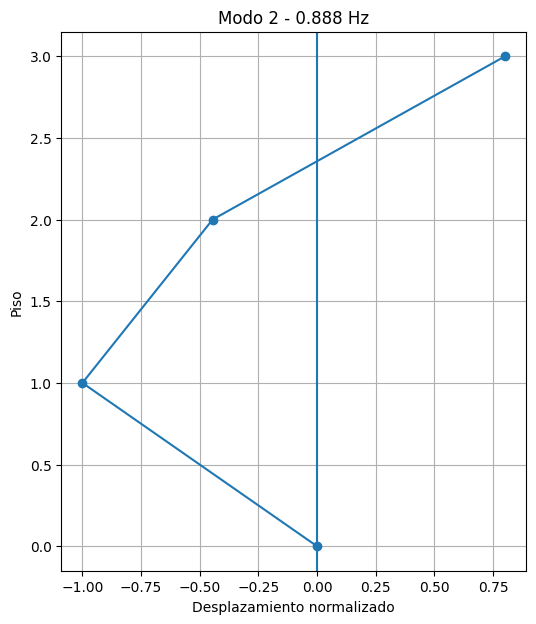

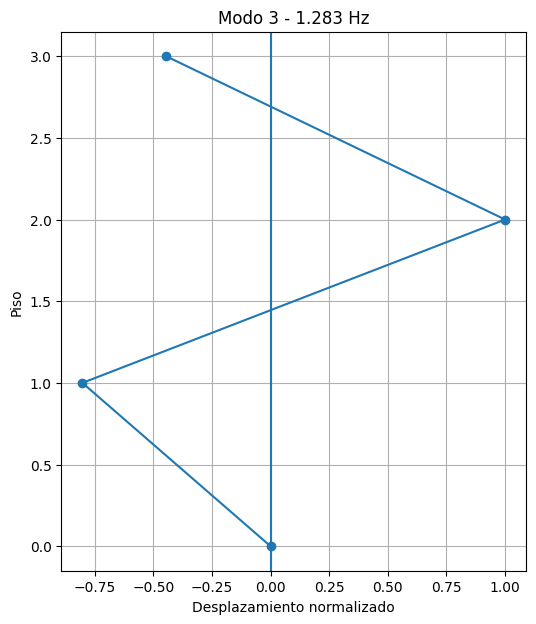

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh

eigenvalues, modes = eigh(K, M)

omega = np.sqrt(eigenvalues)

frequencies = omega / (2*np.pi)

floors = np.array([0, 1, 2, 3])

for i in range(3):

    mode = modes[:, i]

    # Añadimos el suelo, cuyo desplazamiento es 0
    shape = np.concatenate([
        [0],
        mode
    ])

    # Normalización para visualizar
    shape = shape / np.max(np.abs(shape))

    plt.figure(figsize=(6, 7))

    plt.plot(
        shape,
        floors,
        marker="o"
    )

    plt.axvline(0)

    plt.xlabel("Desplazamiento normalizado")
    plt.ylabel("Piso")

    plt.title(
        f"Modo {i+1} - "
        f"{frequencies[i]:.3f} Hz"
    )

    plt.grid()

    plt.show()

Cada gráfico representa una manera diferente en la que la estructura puede oscilar.

En problemas reales de ingeniería estructural puede haber:

$10^3,\;10^5,\;10^6$

o incluso más grados de libertad.

Ahí el álgebra lineal numérica se vuelve fundamental.

# 21. ¿Y dónde aparece Scientific Machine Learning?

Ahora llegamos al motivo por el que estás aprendiendo esto.

Supongamos que tenemos el edificio:

$M\ddot{x}+C\dot{x}+Kx=f(t)$

Pero no conocemos perfectamente $(K)$ o $(C)$.

Tenemos sensores que miden:

$x_{\text{observado}}(t)$

Podemos construir un modelo:

$M\ddot{x}_{modelo}
+
C_\theta\dot{x}_{modelo}
+
K_\theta x_{modelo}
=$
$f(t)
$

donde $(\theta)$ contiene parámetros desconocidos.

Entrenamos buscando:

$$
\theta^*
=
\arg\min_{\theta}
\sum_i
\left\|
x_{\text{modelo}}(t_i;\theta)
-
x_{\text{observado}}(t_i)
\right\|^2
$$

Eso significa:

$\boxed{
\text{datos}
+
\text{ODE}
+
\text{álgebra lineal}
+
\text{optimización}
}
$

Y ya estamos entrando en **Scientific Machine Learning**.

Más adelante incluso puedes reemplazar una parte desconocida de la física por una red neuronal:

$
\dot{x}
=$
$f_{\text{física}}(x,t)
+
NN_\theta(x,t)
$

La red aprende la parte de la dinámica que el modelo físico no representa adecuadamente.

# 22. La conexión completa que quiero que tengas en la cabeza

Cuando estudies estos temas, evita memorizarlos como capítulos independientes.

Piensa en esta cadena:

$
\boxed{
\text{fenómeno físico}
}
$

$\downarrow
$

$\boxed{
\text{ecuación diferencial}
}$

$\downarrow$

$\boxed{
\dot{x}=Ax
}$

$\downarrow$

$\boxed{
\text{matrices + vectores}
}$

$\downarrow$

$\boxed{
\text{autovalores + autovectores}
}$

$\downarrow$

$\boxed{
e^{At}
}$

$\downarrow$
$
\boxed{
\text{estabilidad + oscilaciones + dinámica}
}$

$
\downarrow
$

$\boxed{
\text{solución numérica con ODE solvers}
}$

$
\downarrow
$

$
\boxed{
\text{datos experimentales}
}
$

$
\downarrow
$

$\boxed{
\text{estimación de parámetros}
}
$

$
\downarrow
$

$
\boxed{
\text{Scientific Machine Learning}
}
$

Ese último salto es precisamente hacia donde estás estudiando.

| **Inicio**         | **atrás 2**                          | **Siguiente 4**                                    |
| ------------------ | ------------------------------------ | -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./5_2_Sistemas_dinamicos.ipynb) | [⏩](./5_4_Fourier.ipynb) |